# 01 - JPL Horizons exploration: Sun and Earth over lunar landing sites

**Goal:** understand the Sun/Earth azimuth-elevation tables that drive the *Lunar Landing Site Navigator*
(solar power potential and direct-to-Earth comms windows).

Data: `data/raw/horizons/<site>_<body>.csv`, hourly, 2026-01-01 to 2027-01-01, columns `time_utc, az_deg, el_deg, range_km`.
Fetched with `data.horizons.observer_table` (topocentric, apparent az/el).

**Caveat throughout:** elevation is measured against the *smooth ellipsoid horizon*. Real terrain (crater rims, ridges)
blocks or extends visibility. That matters hugely near the south pole, where the Sun and Earth skim the horizon.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from data.horizons import SITES

RAW = ROOT / "data" / "raw" / "horizons"
BODIES = ["sun", "earth"]
D = {(s, b): pd.read_csv(RAW / f"{s}_{b}.csv", parse_dates=["time_utc"]) for s in SITES for b in BODIES}

# Order sites from pole to equator for every table and plot
SITES = dict(sorted(SITES.items(), key=lambda kv: kv[1][0]))
POLAR = [s for s, (lat, _) in SITES.items() if lat < -85]
pd.DataFrame(SITES, index=["lat_deg", "lon_east_deg"]).T

,lat_deg,lon_east_deg
site04_shackleton_rim,-89.76300,187.99760
site01_connecting_ridge,-89.46320,222.51040
im1_odysseus,-80.13000,1.44000
chandrayaan3,-69.37300,32.31900
change4,-45.44460,177.59910
apollo11,0.67408,23.47297
apollo17,20.19110,30.77230
apollo15,26.13222,3.63386


## 1. Sanity checks: shape, dtypes, gaps, value ranges

In [2]:
rows = []
for (s, b), d in D.items():
    dt = d.time_utc.diff().dropna()
    rows.append(dict(site=s, body=b, n=len(d), nans=int(d.isna().sum().sum()), dups=int(d.time_utc.duplicated().sum()),
                     step_min=dt.min(), step_max=dt.max(), t0=d.time_utc.iloc[0], t1=d.time_utc.iloc[-1],
                     az_min=d.az_deg.min(), az_max=d.az_deg.max(), el_min=d.el_deg.min(), el_max=d.el_deg.max(),
                     range_min_km=d.range_km.min(), range_max_km=d.range_km.max()))
sanity = pd.DataFrame(rows).set_index(["site", "body"])
print(D[("apollo11", "sun")].dtypes, "\n")
# all files share one identical time grid -> Sun and Earth line up row by row
T = D[("apollo11", "sun")].time_utc
assert all(d.time_utc.equals(T) for d in D.values())
assert (sanity.nans == 0).all() and (sanity.dups == 0).all() and (sanity.step_max == pd.Timedelta("1h")).all()
print("time span:", T.iloc[0], "->", T.iloc[-1], "| step:", T.diff().dropna().unique())
sanity.drop(columns=["step_min", "step_max", "t0", "t1"]).round(2)

time_utc    datetime64[us]
az_deg             float64
el_deg             float64
range_km           float64
dtype: object 

time span: 2026-01-01 00:00:00 -> 2027-01-01 00:00:00 | step: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[us]


n  nans  dups  az_min  az_max  el_min  \
site                    body                                              
site01_connecting_ridge sun    8761     0     0    0.02  359.99   -2.11   
                        earth  8761     0     0  129.59  145.06   -7.52   
site04_shackleton_rim   sun    8761     0     0    0.02  359.98   -1.82   
                        earth  8761     0     0  164.07  179.60   -7.34   
im1_odysseus            sun    8761     0     0    0.05  359.86  -11.35   
                        earth  8761     0     0    0.00  360.00    2.76   
chandrayaan3            sun    8761     0     0    0.01  359.93  -22.11   
                        earth  8761     0     0  316.57  334.57   10.19   
change4                 sun    8761     0     0    0.08  359.92  -46.14   
                        earth  8761     0     0  172.67  195.13  -51.52   
apollo11                sun    8761     0     0    4.99  355.62  -89.82   
                        earth  8761     0     0  251.00  288.48   57.97   
apollo15                sun    8761     0     0    0.09  359.99  -65.41   
                        earth  8761     0     0  169.23  204.54   55.73   
apollo17                sun    8761     0     0    0.32  359.90  -71.33   
                        earth  8761     0     0  228.11  251.57   43.94   

                               el_max  range_min_km  range_max_km  
site                    body                                       
site01_connecting_ridge sun      2.05  1.467943e+08  1.524789e+08  
                        earth    6.14  3.565255e+05  4.065793e+05  
site04_shackleton_rim   sun      1.78  1.467944e+08  1.524789e+08  
                        earth    6.29  3.565206e+05  4.065745e+05  
im1_odysseus            sun     11.39  1.467947e+08  1.524786e+08  
                        earth   16.40  3.562186e+05  4.062688e+05  
chandrayaan3            sun     22.16  1.467949e+08  1.524784e+08  
                        earth   23.93  3.560059e+05  4.060431e+05  
change4                 sun     46.10  1.467932e+08  1.524801e+08  
                        earth  -37.93  3.577667e+05  4.077211e+05  
apollo11                sun     89.88  1.467961e+08  1.524774e+08  
                        earth   73.95  3.550648e+05  4.048210e+05  
apollo15                sun     65.45  1.467960e+08  1.524773e+08  
                        earth   70.64  3.551652e+05  4.047961e+05  
apollo17                sun     71.39  1.467959e+08  1.524775e+08  
                        earth   62.95  3.553044e+05  4.049728e+05

In [3]:
# Physical plausibility: Sun ~1 AU, Earth ~ Earth-Moon distance; max Sun elevation ~ 90 - |lat| + 1.54 deg (lunar axial tilt)
sun_r = sanity.xs("sun", level="body")[["range_min_km", "range_max_km"]] / 149597870.7
earth_r = sanity.xs("earth", level="body")[["range_min_km", "range_max_km"]]
lat = pd.Series({s: v[0] for s, v in SITES.items()})
check = pd.DataFrame({"sun_range_au_min": sun_r.range_min_km, "sun_range_au_max": sun_r.range_max_km,
                      "earth_range_kkm_min": earth_r.range_min_km / 1e3, "earth_range_kkm_max": earth_r.range_max_km / 1e3,
                      "one_way_light_s_max": earth_r.range_max_km / 299792.458,
                      "sun_el_max": sanity.xs("sun", level="body").el_max, "expected_~": np.minimum(90, 90 - lat.abs() + 1.54)})
check.loc[list(SITES)].round(3)

,sun_range_au_min,sun_range_au_max,earth_range_kkm_min,earth_range_kkm_max,one_way_light_s_max,sun_el_max,expected_~
site04_shackleton_rim,0.981,1.019,356.521,406.575,1.356,1.777,1.777
site01_connecting_ridge,0.981,1.019,356.525,406.579,1.356,2.050,2.077
im1_odysseus,0.981,1.019,356.219,406.269,1.355,11.393,11.410
chandrayaan3,0.981,1.019,356.006,406.043,1.354,22.165,22.167
change4,0.981,1.019,357.767,407.721,1.360,46.099,46.095
apollo11,0.981,1.019,355.065,404.821,1.350,89.883,90.000
apollo17,0.981,1.019,355.304,404.973,1.351,71.388,71.349
apollo15,0.981,1.019,355.165,404.796,1.350,65.454,65.408


**Sanity verdict:** all 16 files have 8761 rows on an identical, gap-free hourly grid (the stop time is inclusive),
no NaNs or duplicates, numeric dtypes, and physically sensible values: the Sun at ~0.98-1.02 AU, Earth at the Earth-Moon distance
(~1.2-1.35 s one-way light time, i.e. the comms latency), and peak Sun elevation matching 90 deg - |latitude| + 1.54 deg (the Moon's small axial tilt).

### Azimuth wraparound

Azimuth lives on a circle (0 = 360 = north). Naive differences or averages break when a track crosses north.
Two cases show up here:
* polar sites: the Sun circles the whole horizon once per lunar day, so it crosses 0/360 every month;
* near-zenith passes (Apollo 11, lat 0.7 deg): the Sun passes almost overhead and azimuth flips from east to west within hours.

In [4]:
def circ_diff(a):
    """Hour-to-hour azimuth change in (-180, 180]."""
    return (np.diff(a) + 180) % 360 - 180

def ang_step(d):
    """Great-circle angle (deg) moved between consecutive samples."""
    az, el = np.radians(d.az_deg.values), np.radians(d.el_deg.values)
    c = np.sin(el[1:]) * np.sin(el[:-1]) + np.cos(el[1:]) * np.cos(el[:-1]) * np.cos(np.diff(az))
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

rows = []
for (s, b), d in D.items():
    raw = np.abs(np.diff(d.az_deg.values))
    rows.append(dict(site=s, body=b, wraps_0_360=int((raw > 180).sum()),
                     az_jumps_gt20deg_per_h=int((np.abs(circ_diff(d.az_deg.values)) > 20).sum()),
                     median_sky_motion_deg_per_h=np.median(ang_step(d))))
motion = pd.DataFrame(rows).set_index(["site", "body"]).unstack("body").loc[list(SITES)]
motion.round(3)

wraps_0_360     az_jumps_gt20deg_per_h      \
body                          earth sun                  earth sun   
site                                                                 
site04_shackleton_rim             0  12                      0   0   
site01_connecting_ridge           0  12                      0   0   
im1_odysseus                     27  13                      0   0   
chandrayaan3                      0  13                      0   0   
change4                           0  12                      0   0   
apollo11                          0  13                      0  41   
apollo17                          0  12                      0   0   
apollo15                          0  12                      0   0   

                        median_sky_motion_deg_per_h         
body                                          earth    sun  
site                                                        
site04_shackleton_rim                         0.061  0.508  
site01_connecting_ridge                       0.061  0.508  
im1_odysseus                                  0.061  0.508  
chandrayaan3                                  0.061  0.508  
change4                                       0.061  0.508  
apollo11                                      0.062  0.508  
apollo17                                      0.062  0.508  
apollo15                                      0.062  0.508

* The Sun moves ~0.5 deg/hour across the sky everywhere (360 deg per 29.5-day lunar day). Earth moves ~0.06 deg/hour (about 8x slower)
  and, more importantly, only wobbles inside a small box instead of circling the sky (see section 4).
* Apollo 11's large hourly azimuth jumps are the zenith pass, not bad data: when the Sun is almost overhead, azimuth is ill-defined.
* **App implication:** never interpolate or average azimuth linearly. Use circular differences / unit vectors, and break sky-track lines at 0/360.

## 2. Sun and Earth elevation over time: polar vs equatorial

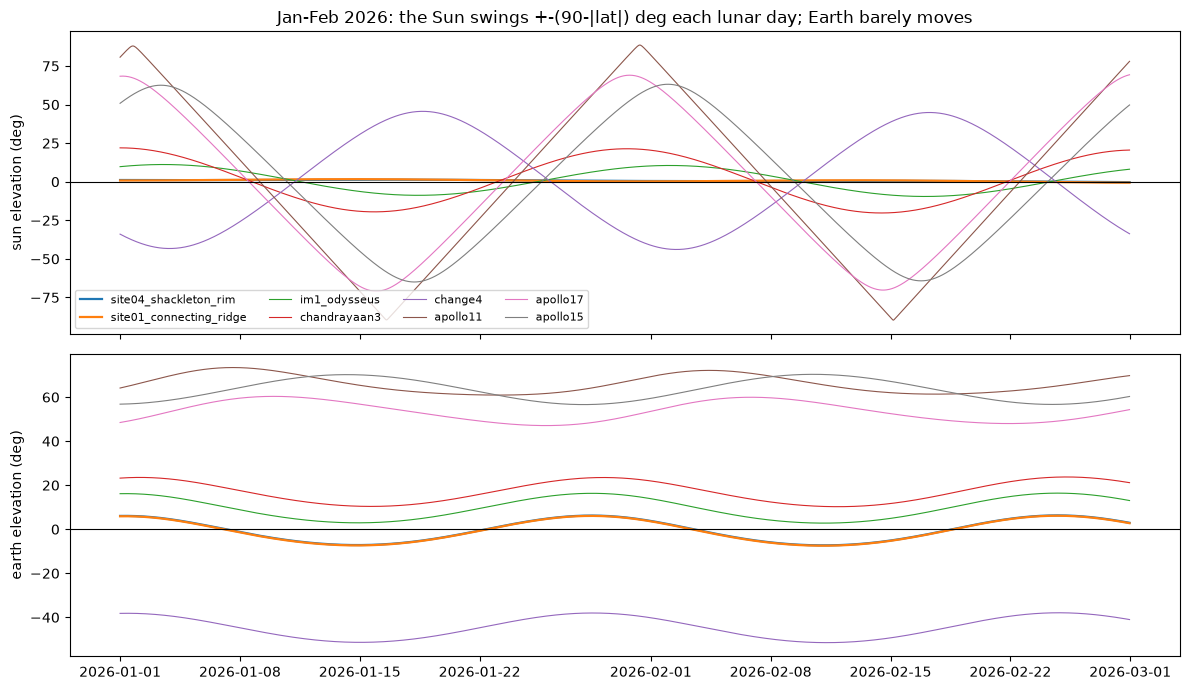

In [5]:
win = (T >= "2026-01-01") & (T < "2026-03-01")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, b in zip(axes, BODIES):
    for s in SITES:
        ax.plot(T[win], D[(s, b)].el_deg[win], lw=1.6 if s in POLAR else 0.8, label=s)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel(f"{b} elevation (deg)")
axes[0].legend(ncol=4, fontsize=8, loc="lower left")
axes[0].set_title("Jan-Feb 2026: the Sun swings +-(90-|lat|) deg each lunar day; Earth barely moves")
plt.tight_layout()

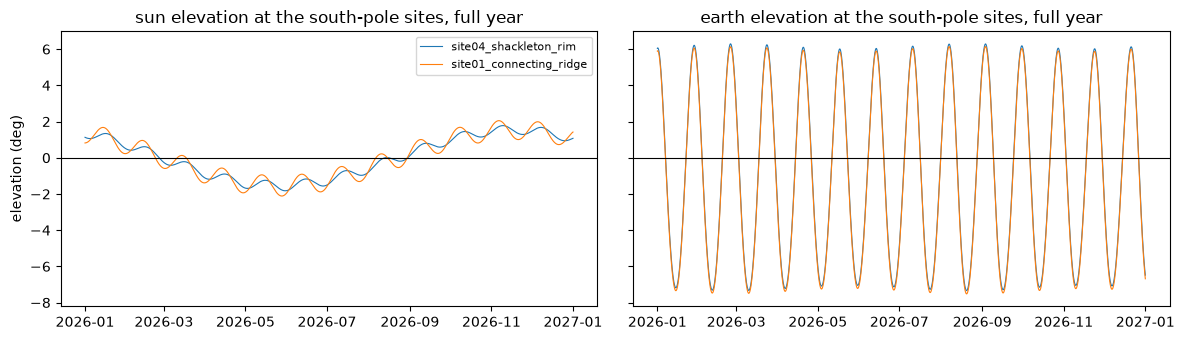

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, b in zip(axes, BODIES):
    for s in POLAR:
        ax.plot(T, D[(s, b)].el_deg, lw=0.8, label=s)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{b} elevation at the south-pole sites, full year")
axes[0].set_ylabel("elevation (deg)"); axes[0].legend(fontsize=8)
plt.tight_layout()

* **Equatorial/mid-latitude sites** (Apollo 11/15/17): a clean ~14.8-day day / ~14.8-day night square wave with the Sun climbing high.
* **Polar sites**: the Sun never gets more than ~2 deg above or below the horizon. Its elevation is dominated by the
  seasonal swing of the subsolar latitude (+-1.54 deg over a ~346-day cycle), with only a small monthly ripple on top.
  On a smooth horizon this gives months of continuous light followed by months of continuous darkness,
  but real terrain (a 1-2 deg rim) completely changes the picture. Horizon masks from the DEMs are essential there.
* **Earth** is always up at near-side sites, never up at Chang'e 4 (far side), and grazes the horizon (+-7 deg) at the poles.

## 3. Rise/set events and visibility windows (smooth horizon)

Horizon crossings are found by linearly interpolating `el_deg` between hourly samples, which gives event times to within minutes.
Windows touching the start or end of the year are truncated and excluded from median-duration statistics.

In [7]:
T0 = T.iloc[0]
H = ((T - T0) / pd.Timedelta("1h")).values  # hours since 2026-01-01

def windows(el, h=H):
    """Split the record into alternating up/down windows at interpolated horizon crossings."""
    el = np.asarray(el, float)
    up = el > 0
    i = np.flatnonzero(up[1:] != up[:-1])
    tc = h[i] + (h[i + 1] - h[i]) * el[i] / (el[i] - el[i + 1])
    edges = np.r_[h[0], tc, h[-1]]
    w = pd.DataFrame({"start_h": edges[:-1], "end_h": edges[1:], "up": np.r_[up[0], up[i + 1]]})
    w["dur_h"] = w.end_h - w.start_h
    w["complete"] = True
    w.loc[[0, len(w) - 1], "complete"] = False
    return w

# self-check: fraction of time up from windows matches the fraction of samples above the horizon
for s in SITES:
    w = windows(D[(s, "sun")].el_deg)
    assert abs(w[w.up].dur_h.sum() / w.dur_h.sum() - (D[(s, "sun")].el_deg > 0).mean()) < 0.01, s

In [8]:
def summarize(el):
    w = windows(el)
    c = w[w.complete]
    return pd.Series({"frac_up": (np.asarray(el) > 0).mean(),
                      "rises": int((w.up & (w.index > 0)).sum()),
                      "up_median_d": c[c.up].dur_h.median() / 24, "up_max_d": w[w.up].dur_h.max() / 24,
                      "down_median_d": c[~c.up].dur_h.median() / 24, "down_max_d": w[~w.up].dur_h.max() / 24})

sun_tab = pd.DataFrame({s: summarize(D[(s, "sun")].el_deg) for s in SITES}).T
earth_tab = pd.DataFrame({s: summarize(D[(s, "earth")].el_deg) for s in SITES}).T
print("SUN: rises = sunrises in 2026; durations in days; max includes truncated windows")
display(sun_tab.round(2))
print("EARTH")
display(earth_tab.round(2))

SUN: rises = sunrises in 2026; durations in days; max includes truncated windows


,frac_up,rises,up_median_d,up_max_d,down_median_d,down_max_d
site04_shackleton_rim,0.50,2.0,2.83,123.62,91.57,168.96
site01_connecting_ridge,0.53,3.0,7.68,123.87,16.44,141.97
im1_odysseus,0.52,12.0,14.80,16.25,14.73,16.15
chandrayaan3,0.51,12.0,14.79,15.48,14.74,15.38
change4,0.49,13.0,14.74,15.02,14.79,15.01
apollo11,0.51,12.0,14.78,14.83,14.74,14.78
apollo17,0.51,12.0,14.78,14.85,14.74,14.87
apollo15,0.51,12.0,14.79,14.88,14.74,14.89


EARTH


,frac_up,rises,up_median_d,up_max_d,down_median_d,down_max_d
site04_shackleton_rim,0.45,13.0,12.11,12.35,15.11,15.34
site01_connecting_ridge,0.44,13.0,11.91,12.16,15.32,15.55
im1_odysseus,1.00,0.0,NaN,365.00,NaN,NaN
chandrayaan3,1.00,0.0,NaN,365.00,NaN,NaN
change4,0.00,0.0,NaN,NaN,NaN,365.00
apollo11,1.00,0.0,NaN,365.00,NaN,NaN
apollo17,1.00,0.0,NaN,365.00,NaN,NaN
apollo15,1.00,0.0,NaN,365.00,NaN,NaN


In [9]:
# Length of the lunar day: sunrise-to-sunrise interval
rows = {}
for s in SITES:
    w = windows(D[(s, "sun")].el_deg)
    rises = w.start_h[w.up & (w.index > 0)].values
    if s not in POLAR and len(rises) > 2:
        rows[s] = pd.Series(np.diff(rises) / 24).describe()[["count", "mean", "min", "max"]]
synodic = pd.DataFrame(rows).T
assert abs(synodic.loc["apollo15", "mean"] - 29.53) < 0.1
synodic.round(2)

,count,mean,min,max
im1_odysseus,11.0,29.50,29.11,29.97
chandrayaan3,11.0,29.51,29.30,29.76
change4,12.0,29.53,29.40,29.66
apollo11,11.0,29.52,29.45,29.60
apollo17,11.0,29.52,29.47,29.59
apollo15,11.0,29.52,29.47,29.59


* At non-polar sites the lunar day is the **synodic month, ~29.5 Earth days** sunrise to sunrise (it varies by a few tenths of a day
  because the Moon's orbit is elliptical): roughly **14.8 days of sunlight then 14.8 days of night**, ~51% sunlit, 12-13 sunrises per year.
* Night length (~350 h) is the design driver for batteries/heaters at those sites.
* At the polar sites there are only 2-3 sunrises per year: the smooth-horizon Sun stays up for up to ~124 days and down for up to
  ~140-170 days at a stretch. These numbers are *not* realistic for site selection; they only say
  "the Sun skims the horizon here".
* Earth: near-side sites have Earth up 100% of the time (a single truncated window). Chang'e 4 never sees Earth.
  The south-pole sites see Earth ~44% of the time: 13 Earthrises per year, ~12-day visible windows and ~15-day gaps,
  a ~27-day cycle set by libration in latitude (next section).

## 4. Earth's libration wobble

From the Moon, Earth does not rise and set daily. It stays near one point in the sky and wobbles by several degrees
(optical libration: ~+-7.9 deg in longitude, ~+-6.7 deg in latitude) over roughly a month.

In [10]:
def az_centered(a):
    """Azimuth relative to its circular mean, in (-180, 180], so tracks that cross north stay continuous."""
    m = np.degrees(np.angle(np.exp(1j * np.radians(a)).mean()))
    return (a - m + 180) % 360 - 180, m % 360

rows = {}
for s in SITES:
    e, sun = D[(s, "earth")], D[(s, "sun")]
    daz, m = az_centered(e.az_deg.values)
    rows[s] = {"earth_az_center": m, "earth_az_span": daz.max() - daz.min(), "earth_el_min": e.el_deg.min(),
               "earth_el_max": e.el_deg.max(), "earth_el_span": e.el_deg.max() - e.el_deg.min(),
               "sun_el_span": sun.el_deg.max() - sun.el_deg.min()}
lib = pd.DataFrame(rows).T
lib.round(2)

,earth_az_center,earth_az_span,earth_el_min,earth_el_max,earth_el_span,sun_el_span
site04_shackleton_rim,172.11,15.52,-7.34,6.29,13.63,3.60
site01_connecting_ridge,137.59,15.47,-7.52,6.14,13.66,4.16
im1_odysseus,358.63,15.82,2.76,16.40,13.64,22.75
chandrayaan3,326.08,18.00,10.19,23.93,13.74,44.27
change4,183.69,22.46,-51.52,-37.93,13.59,92.24
apollo11,269.87,37.48,57.97,73.95,15.98,179.70
apollo17,240.36,23.46,43.94,62.95,19.01,142.72
apollo15,187.59,35.31,55.73,70.64,14.92,130.86


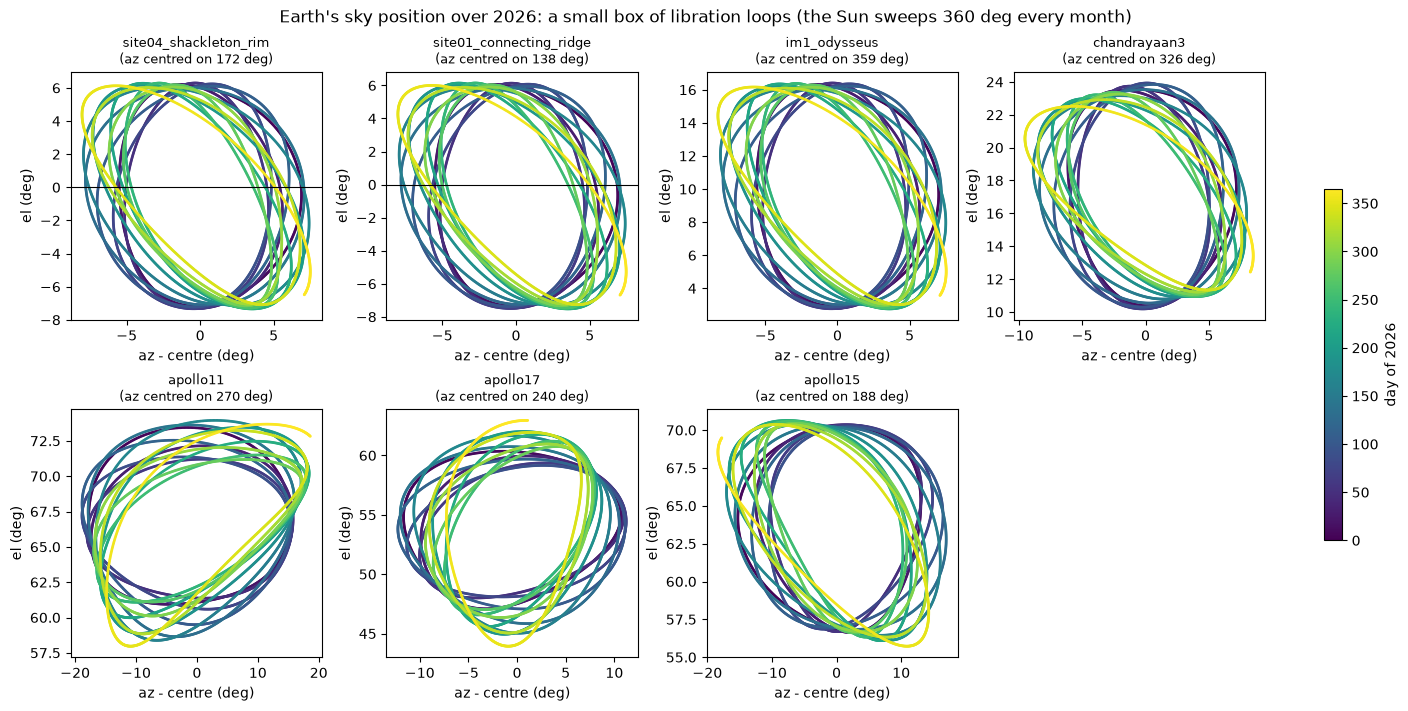

In [11]:
near = [s for s in SITES if s != "change4"]
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout="constrained")
for ax, s in zip(axes.flat, near):
    e = D[(s, "earth")]
    daz, m = az_centered(e.az_deg.values)
    sc = ax.scatter(daz, e.el_deg, c=H / 24, s=1, cmap="viridis")
    if e.el_deg.min() < 1:
        ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{s}\n(az centred on {m:.0f} deg)", fontsize=9)
    ax.set_xlabel("az - centre (deg)"); ax.set_ylabel("el (deg)")
axes.flat[-1].axis("off")
fig.colorbar(sc, ax=axes, label="day of 2026", shrink=0.6)
fig.suptitle("Earth's sky position over 2026: a small box of libration loops (the Sun sweeps 360 deg every month)");

,frac_el>0,frac_el>1,frac_el>2,frac_el>3,frac_el>5
site04_shackleton_rim,0.447,0.400,0.351,0.299,0.174
site01_connecting_ridge,0.440,0.392,0.343,0.291,0.162


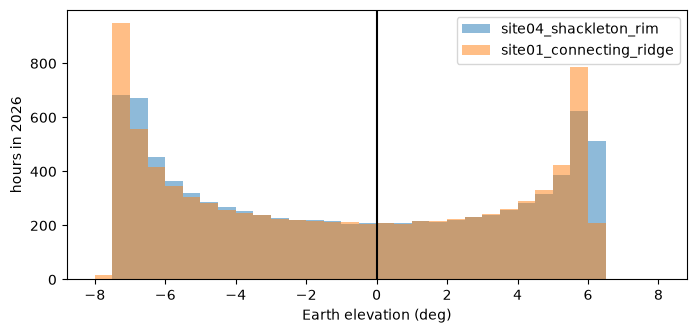

In [12]:
# How close to the horizon is Earth at the south-pole sites?
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(-8, 8.5, 0.5)
rows = {}
for s in POLAR:
    el = D[(s, "earth")].el_deg
    ax.hist(el, bins=bins, alpha=0.5, label=s)
    rows[s] = {f"frac_el>{k}": (el > k).mean() for k in (0, 1, 2, 3, 5)}
ax.axvline(0, color="k"); ax.set_xlabel("Earth elevation (deg)"); ax.set_ylabel("hours in 2026"); ax.legend()
pd.DataFrame(rows).T.round(3)

* Earth's sky position at any near-side site is confined to a box of **~14-19 deg in elevation** and 15-37 deg in azimuth all year
  (azimuth spans look larger where Earth is high in the sky, since azimuth degrees shrink toward the zenith), compared with the Sun's full 360 deg sweep. At IM-1 (Odysseus) Earth sits near due north, so its raw azimuth wraps 0/360
  constantly; centring on the circular mean fixes that.
* At the south-pole sites Earth's elevation stays between about **-7.5 and +6.3 deg** and is above the smooth horizon only ~44% of the time,
  more than 2 deg up ~35% and more than 5 deg up only ~17% (table above). A modest terrain rise in Earth's direction would remove most DTE windows:
  **comms at polar sites are a terrain question first.**
* Earth's azimuth differs a lot between the two pole sites (~137 deg vs ~172 deg) although they are only ~11 km apart:
  near the pole, azimuth is extremely sensitive to longitude.

## 5. Sky tracks (azimuth vs elevation) over one lunar day

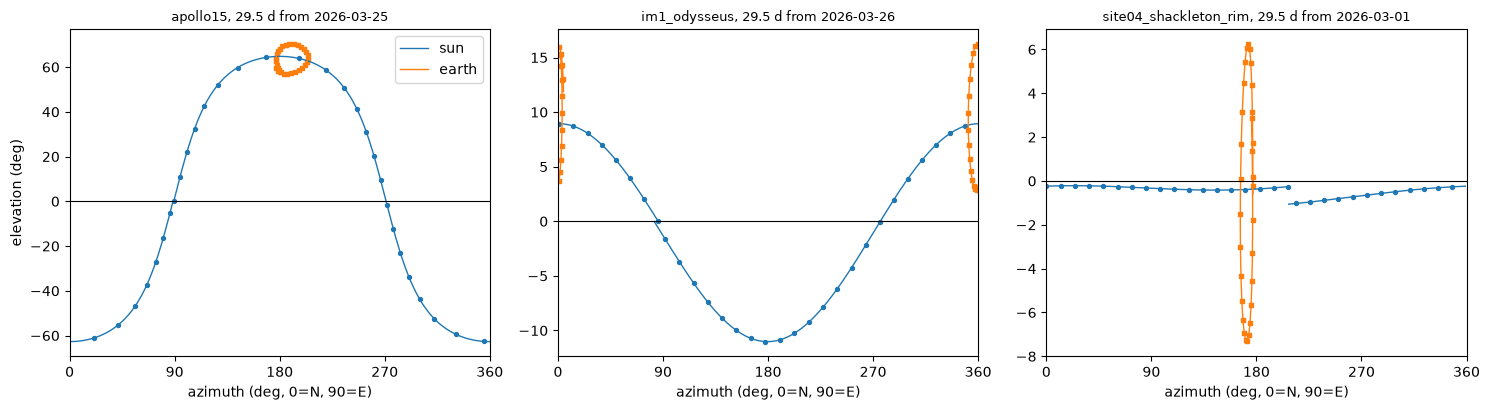

In [13]:
def one_lunar_day(s, start="2026-03-01"):
    """Mask from the first sunrise after `start` to the next one (fallback: a fixed 29.53 d, e.g. polar sites)."""
    w = windows(D[(s, "sun")].el_deg)
    h0 = (pd.Timestamp(start) - T0) / pd.Timedelta("1h")
    r = w[w.up & (w.start_h > h0) & (w.index > 0)].start_h.values
    a, b = (r[0], r[1]) if len(r) > 1 and 28 * 24 < r[1] - r[0] < 31 * 24 else (h0, h0 + 29.53 * 24)
    return (H >= a) & (H <= b)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, s in zip(axes, ["apollo15", "im1_odysseus", "site04_shackleton_rim"]):
    m = one_lunar_day(s)
    for b, mk in [("sun", "o"), ("earth", "s")]:
        d = D[(s, b)][m]
        az = d.az_deg.values.astype(float).copy()
        az[1:][np.abs(np.diff(az)) > 180] = np.nan  # break the line at the 0/360 seam
        ax.plot(az, d.el_deg, lw=1, label=b)
        ax.scatter(d.az_deg[::24], d.el_deg[::24], s=8, marker=mk)  # one marker per Earth day
    ax.axhline(0, color="k", lw=0.8); ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 90))
    ax.set_title(f"{s}, 29.5 d from {T[m].iloc[0]:%Y-%m-%d}", fontsize=9); ax.set_xlabel("azimuth (deg, 0=N, 90=E)")
axes[0].set_ylabel("elevation (deg)"); axes[0].legend()
plt.tight_layout()

* **Apollo 15** (26 deg N): the Sun rises in the east, arcs through the south to ~65 deg and sets in the west after ~14.8 days
  (markers are 24 h apart), then continues below the horizon; Earth is a near-stationary dot high in the south.
* **IM-1** (80 deg S): the Sun circles low around the horizon, peaking only ~10 deg in the north; Earth sits low (~3-16 deg) near due north.
* **Shackleton rim**: the Sun circles the full horizon at near-constant elevation (a fraction-of-a-degree monthly ripple). In this March window it stays
  just below the smooth horizon the whole time; whether it is really 'up' depends entirely on the terrain profile at each azimuth: this plot is exactly what the app should overlay on a horizon mask.

## 6. Sketch: "time remaining until sunset / Earthset" from any instant

The app's key metric: given a site and a candidate landing time, how long until the Sun (power) or Earth (comms) is lost,
or, if currently down, how long until it returns. With the window table this is a `searchsorted` lookup.

In [14]:
def time_remaining(el, t):
    """For instants `t`: (is_up, hours until the current window ends). NaN if that window runs past the data."""
    w = windows(el)
    h = np.asarray((pd.DatetimeIndex(np.atleast_1d(t)) - T0) / pd.Timedelta("1h"), float)
    k = np.clip(np.searchsorted(w.start_h.values, h, side="right") - 1, 0, len(w) - 1)
    rem = w.end_h.values[k] - h
    rem[k == len(w) - 1] = np.nan  # last window is truncated at the end of the data
    return w.up.values[k], rem

# self-check: just after an Apollo 15 sunrise, almost a full lunar day remains
w15 = windows(D[("apollo15", "sun")].el_deg)
r0 = w15[w15.up & w15.complete].iloc[0]
up, rem = time_remaining(D[("apollo15", "sun")].el_deg, T0 + pd.Timedelta(hours=r0.start_h + 1))
assert up[0] and abs(rem[0] - (r0.dur_h - 1)) < 1e-6

t = pd.Timestamp("2026-06-15 12:00")
for s in ["apollo15", "im1_odysseus", "site04_shackleton_rim"]:
    for b in BODIES:
        up, rem = time_remaining(D[(s, b)].el_deg, t)
        msg = "past end of data (always up)" if np.isnan(rem[0]) else f"{rem[0] / 24:6.2f} d until {'set' if up[0] else 'rise'}"
        print(f"{s:24s} {b:5s} at {t}: {'UP  ' if up[0] else 'DOWN'}  {msg}")

apollo15                 sun   at 2026-06-15 12:00:00: DOWN    6.65 d until rise
apollo15                 earth at 2026-06-15 12:00:00: UP    past end of data (always up)
im1_odysseus             sun   at 2026-06-15 12:00:00: DOWN    7.53 d until rise
im1_odysseus             earth at 2026-06-15 12:00:00: UP    past end of data (always up)
site04_shackleton_rim    sun   at 2026-06-15 12:00:00: DOWN   58.87 d until rise
site04_shackleton_rim    earth at 2026-06-15 12:00:00: UP      3.94 d until set


,median_days_left,p10_days_left
apollo11,7.14,1.43
apollo15,7.20,1.43
apollo17,7.12,1.43
chandrayaan3,7.12,1.43
im1_odysseus,7.23,1.45


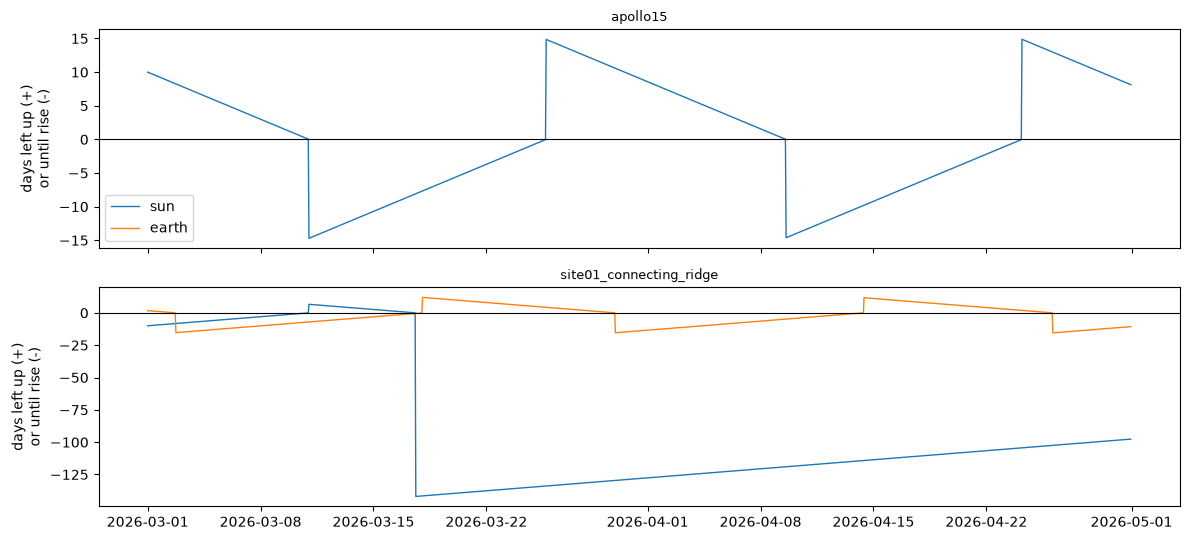

In [15]:
m = (T >= "2026-03-01") & (T < "2026-05-01")
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for ax, s in zip(axes, ["apollo15", "site01_connecting_ridge"]):
    for b in BODIES:
        up, rem = time_remaining(D[(s, b)].el_deg, T[m])
        ax.plot(T[m], np.where(up, rem, -rem) / 24, lw=1, label=b)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(s, fontsize=9)
    ax.set_ylabel("days left up (+)\nor until rise (-)")
axes[0].legend(); plt.tight_layout()

# If you land at a random sunlit instant, how much daylight is left?
rows = {}
for s in ["apollo11", "apollo15", "apollo17", "chandrayaan3", "im1_odysseus"]:
    up, rem = time_remaining(D[(s, "sun")].el_deg, T)
    r = rem[up & ~np.isnan(rem)] / 24
    rows[s] = {"median_days_left": np.median(r), "p10_days_left": np.percentile(r, 10)}
pd.DataFrame(rows).T.round(2)

* The metric is a sawtooth: it jumps to ~14.8 d at sunrise and ramps down to 0 at sunset (shown negative while waiting for the next rise).
  Landing at a random sunlit moment leaves ~7.1-7.2 days median (and under 1.5 days 10% of the time) at the low-latitude sites, so planners should target landings shortly after
  local sunrise (as Apollo did, also for low Sun angles) to maximize the remaining day.
* For Earth at near-side sites the answer is simply "always up"; at the pole sites Earth gives a ~1-2 week sawtooth.
* **App implication:** precompute the window table per site/body once (tens of rows per year), then any instant is an O(log n) lookup.
  With a terrain horizon mask, replace `el > 0` with `el > horizon(az)` and the same code works.

## 7. Power + comms together: Sun up AND Earth up

,lat,sun_up,earth_up,both_up,neither_up,longest_both_window_d
site04_shackleton_rim,-89.763,0.498,0.447,0.229,0.284,12.273
site01_connecting_ridge,-89.463,0.525,0.440,0.236,0.271,12.071
im1_odysseus,-80.130,0.515,1.000,0.515,0.000,16.252
chandrayaan3,-69.373,0.507,1.000,0.507,0.000,15.480
change4,-45.445,0.486,0.000,0.000,0.514,0.000
apollo11,0.674,0.509,1.000,0.509,0.000,14.825
apollo17,20.191,0.507,1.000,0.507,0.000,14.851
apollo15,26.132,0.513,1.000,0.513,0.000,14.882


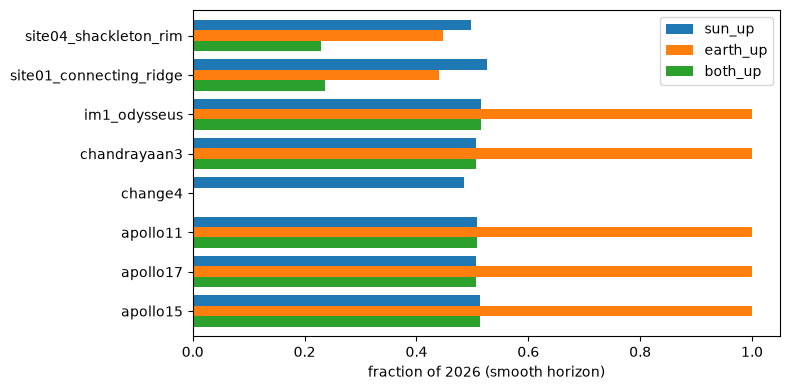

In [16]:
rows = {}
for s in SITES:
    sun, earth = D[(s, "sun")].el_deg.values, D[(s, "earth")].el_deg.values
    both = np.minimum(sun, earth)  # both up <=> the lower of the two is above the horizon
    w = windows(both)
    rows[s] = {"lat": SITES[s][0], "sun_up": (sun > 0).mean(), "earth_up": (earth > 0).mean(), "both_up": (both > 0).mean(),
               "neither_up": ((sun <= 0) & (earth <= 0)).mean(),
               "longest_both_window_d": w[w.up].dur_h.max() / 24 if w.up.any() else 0.0}
both_tab = pd.DataFrame(rows).T
display(both_tab.round(3))

ax = both_tab[["sun_up", "earth_up", "both_up"]].plot.barh(figsize=(8, 4), width=0.8)
ax.set_xlabel("fraction of 2026 (smooth horizon)"); ax.invert_yaxis(); plt.tight_layout()

* Near-side, non-polar sites: Earth is always up, so power+comms availability equals sunlight (~51%), in ~14.8-day windows.
* Chang'e 4 (far side): 0% direct-to-Earth; it needs a relay (Queqiao in reality).
* South-pole sites: Sun and Earth are each up roughly half the time, and their overlap is set by two unrelated cycles
  (solar season vs libration), so simultaneous coverage is only ~23% of the year, in windows of at most ~12 days.
  This is the comparison where terrain-aware horizons will change the ranking most.

## Summary and implications for the app

1. **Data are clean**: 16 x 8761 hourly rows, identical gap-free grid, physically consistent. Hourly resolution is enough for event timing
   (linear interpolation gives minute-level accuracy; the Sun moves only 0.5 deg/h).
2. **Handle azimuth circularly** everywhere (0/360 seam for IM-1 Earth and every polar Sun track; zenith flips at Apollo 11).
3. **Lunar day ~29.5 d** (~14.8 d light / ~14.8 d dark) at non-polar sites; the "time until sunset" metric is a sawtooth and
   a cheap lookup on a precomputed window table.
4. **Earth is nearly fixed** in the sky (small libration box). Its visibility is all-or-nothing except near the limb/poles.
5. **At the south pole both bodies sit within a few degrees of the horizon**, so the visibility test must become `el > horizon_mask(az)`
   from DEM terrain. Smooth-horizon results there are placeholders only.
6. **Far-side sites** should be flagged "no direct-to-Earth" rather than shown as zero windows.